# 2. Datan ymmärtäminen

## 2.1 Backend alustus

Alustetaan backend hyödyntämään tehokkainta reittiä mallin kehittämiseen

In [1]:
%pip install pandas

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
import platform
import pandas as pd

os.environ["KERAS_BACKEND"] = "tensorflow"

import tensorflow as tf

# Apple Silicon Macilla TensorFlow käyttää CPU:ta nopeempaa ja tarkempaa mallia varten
if platform.system() == "Darwin" and platform.machine() == "arm64":
    tf.config.set_visible_devices([], "GPU")

## 2.2 Datan haku ja tulkinta

Haetaan data kerasin avulla ja tarkistellaan sen kokoa ja tyyppejä

In [3]:
import keras
from keras import layers
import numpy as np

# Datan haku ja tulkinta
(x_train, y_train), (x_test, y_test) = keras.datasets.cifar10.load_data()
print(f"x_train: {x_train.shape}")
print(f"y_train: {y_train.shape}")
print(f"x_test: {x_test.shape}")
print(f"y_test: {y_test.shape}")
print(f"Minimi: {x_train.min()}")
print(f"Maksimi: {x_train.max()}")
print(f"Tietotyyppi: {x_train.dtype}")
print(f"Luokat: {np.unique(y_train)}")

# Tyhjät arvot
print("\nTarkistetaan tyhjät arvot:\n")
print("\nTreenidata:\n")
print(f"Treeni kuvien tyhjien arvojen summa: {np.isnan(x_train).sum()}")
print(f"Treeni kuvien kohteiden tyhjien arvojen summa: {np.isnan(y_train).sum()}")
print("\nTestidata\n")
print(f"Testi kuvien tyhjien arvojen summa: {np.isnan(x_test).sum()}")
print(f"Testi kuvien kohteiden tyhjien arvojen summa: {np.isnan(y_test).sum()}")

x_train: (50000, 32, 32, 3)
y_train: (50000, 1)
x_test: (10000, 32, 32, 3)
y_test: (10000, 1)
Minimi: 0
Maksimi: 255
Tietotyyppi: uint8
Luokat: [0 1 2 3 4 5 6 7 8 9]

Tarkistetaan tyhjät arvot:


Treenidata:

Treeni kuvien tyhjien arvojen summa: 0
Treeni kuvien kohteiden tyhjien arvojen summa: 0

Testidata

Testi kuvien tyhjien arvojen summa: 0
Testi kuvien kohteiden tyhjien arvojen summa: 0


## 2.3 Datan tulkinta
CIFAR-10 antaa 60000 kuvaa, joista 50000 menee koulutukseen ja 10000 testaamiseen. Kuvat on koossa 32 x 32 ja 3 värikanavaa. Värit on 0-255 eli 8 bittisiä. Kuvat on jaettu 10 eri luokkaan: 0 = lentokone, 1 = auto, 2 = lintu, 3 = kissa, 4 = peura, 5 = koira, 6 = sammakko, 7 = hevonen, 8 = laiva ja 9 = kuorma-auto [lähde dokumentaatio](https://keras.io/api/datasets/cifar10/?utm_source=chatgpt.com).

Tyhjiä arvoja ei ole datassa.

In [4]:
# Ensimmäiset 10 luokkatunnusta
print("Datan ensimmäisen kymmenen rivin luokkatunnukset:\n")
print(y_train[:10])

# Ensimmäisen kuvan kaikki pikseliarvot
print("\nEnsimmäisen kuvan kaikki pikseliarvot:\n")
print(x_train[0])

# Ensimmäisen kuvan koko ja muoto
print("\nEnsimmäisen kuvan koko 32 x 32 =\n")
print(x_train[0].size)
print("\nEnsimmäisen kuvan muoto\n")
print(x_train[0].shape)

# Ensimmäisen pikselin RGB-arvot
print("\nEsimmäisen pikselin RGB arvot:\n")
print(x_train[0, 0, 0])

Datan ensimmäisen kymmenen rivin luokkatunnukset:

[[6]
 [9]
 [9]
 [4]
 [1]
 [1]
 [2]
 [7]
 [8]
 [3]]

Ensimmäisen kuvan kaikki pikseliarvot:

[[[ 59  62  63]
  [ 43  46  45]
  [ 50  48  43]
  ...
  [158 132 108]
  [152 125 102]
  [148 124 103]]

 [[ 16  20  20]
  [  0   0   0]
  [ 18   8   0]
  ...
  [123  88  55]
  [119  83  50]
  [122  87  57]]

 [[ 25  24  21]
  [ 16   7   0]
  [ 49  27   8]
  ...
  [118  84  50]
  [120  84  50]
  [109  73  42]]

 ...

 [[208 170  96]
  [201 153  34]
  [198 161  26]
  ...
  [160 133  70]
  [ 56  31   7]
  [ 53  34  20]]

 [[180 139  96]
  [173 123  42]
  [186 144  30]
  ...
  [184 148  94]
  [ 97  62  34]
  [ 83  53  34]]

 [[177 144 116]
  [168 129  94]
  [179 142  87]
  ...
  [216 184 140]
  [151 118  84]
  [123  92  72]]]

Ensimmäisen kuvan koko 32 x 32 =

3072

Ensimmäisen kuvan muoto

(32, 32, 3)

Esimmäisen pikselin RGB arvot:

[59 62 63]


## 2.4 Kuvien ja datan tulkinta

Kuvat ovat jo oikeassa muodossa (32 x 32 x 3), värikuvia (pikselit välillä 0-255) ja 3 kanavisia. Tyhjiä arvoja ei ole.

# 3. Datan valmistelu

## 3.1 Nimetään luokat

Määritetään luokkien nimet visualisoinnin helpottamiseski:

In [5]:
# Määritetään luokkien nimet
class_names = [
    "lentokone",
    "auto",
    "lintu",
    "kissa",
    "peura",
    "koira",
    "sammakko",
    "hevonen",
    "laiva",
    "kuorma-auto"
]

## 3.2 Normalisoidaan pikselit

Alustetaan pikselit arvojen 0-1 välille jakamalla koolla 255. Näin neuroverkko oppii paremmin datan piirteet, kun syötearvot ovat pienellä ja yhtenäisellä asteikolla.

In [6]:
# Normalisoidaan pikseliarvot välille 0–1
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

In [7]:
# Datan tarkistus
print(f"Treeni kuvien muoto {x_train.shape}")
print(f"Treeni kuvien luokkien muoto {y_train.shape}")

print(f"Testi kuvien muoto {x_test.shape}")
print(f"Testi kuvien luokkien muoto {y_test.shape}")

# Tarkistetaan normalisoinnin onnistuminen
print(f"Minimi treenidatassa: {x_train.min()}")
print(f"Maksimi treenidatassa: {x_train.max()}")
print(f"Kesiarvo treenidatassa: {x_train.mean()}")

print(f"Minimi testidatassa: {x_test.min()}")
print(f"Maksimi testidatassa: {x_test.max()}")
print(f"Kesiarvo testidatassa: {x_test.mean()}")

Treeni kuvien muoto (50000, 32, 32, 3)
Treeni kuvien luokkien muoto (50000, 1)
Testi kuvien muoto (10000, 32, 32, 3)
Testi kuvien luokkien muoto (10000, 1)
Minimi treenidatassa: 0.0
Maksimi treenidatassa: 1.0
Kesiarvo treenidatassa: 0.4733648896217346
Minimi testidatassa: 0.0
Maksimi testidatassa: 1.0
Kesiarvo testidatassa: 0.4765852391719818


## 3.3 Datan valmistelun johtopäätökset
Pikselit normalisoitiin 0-1 välille ja muoto säilyi ennallaan

# 4. Mallinnus

Luodaan erilaisia malleja saadakseen mahdollisimman tehokas ja tarkka ennustamiseen uuden kuvan mukaan luokittelemaan oikein.

Luodaan ajastusfunktio (AI-generoitu) tallentaakseen ajat selkeästi historiaan.

Lisäksi määritetään yleinen pysäytin.

In [8]:
# AI:lla generoitu timeri saadakseen ajat selkeämmin ajat näkyviin aikavertailuun
import time

class EpochTimer(keras.callbacks.Callback):
    def on_train_begin(self, logs=None):
        self.epoch_times = []

    def on_epoch_begin(self, epoch, logs=None):
        self.start_time = time.perf_counter()

    def on_epoch_end(self, epoch, logs=None):
        elapsed = time.perf_counter() - self.start_time
        self.epoch_times.append(elapsed)

In [9]:
# Erilliset timerit, jotta arvot pysyvät vertailukelpoisina
timer_32_64_2layer = EpochTimer()
timer_64_128_2layer = EpochTimer()
timer_16_32_2layer = EpochTimer()
timer_32_32_64_3layer = EpochTimer()
timer_32_32_64_64_4layer = EpochTimer()
timer_64_64_128_3layer = EpochTimer()

## 4.1 Pysäyttimen määritys

Määritetään stop arvo jotta ei tarvitse kaikkia kierroksia (epochs) käydä, vaan pysäytetään kun malli alkaa ylioppia. Seurataan 3 peräkkäistä validaatio menetyksen (validation loss) -arvoa.

In [10]:
# Määritetään yleinen pysäytin
stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=3,
                                     restore_best_weights=True)

### 4.2 CNN-malli: 32 ja 64 suodatinta
Kokeillaan miten malli kehittyy kaksikerroksisella mallilla, jossa ensimmäinen kerros käyttää 32 suodattinta, antaen 32 piirrekarttaa ja toinen kerrot 64 suodatinta ja 64 eri piirrekarttaa. Kernel koolla 3 ja sisennys arvolla "same". Aktivointi on ReLU ja askelpituutena (stride) oletusarvo 1.

#### 4.2.1 Mallin rakentaminen

In [11]:
keras.utils.set_random_seed(0)
model32_64_2layer = keras.Sequential([
    keras.Input(shape=(32, 32, 3)),
    layers.Conv2D(32, kernel_size=3, padding="same", activation="relu"), # Ensimmäinen kerros 32 suodatinta
    layers.MaxPooling2D(pool_size=2),  # Puolitetaan piirrekarttojen korkeus ja leveys 16 x 16 x 32
    layers.Conv2D(64, kernel_size=3, padding="same", activation="relu"), # Toinen kerros 64 suodatinta
    layers.MaxPooling2D(pool_size=2), # Puolitetaan piirrekarttojen korkeus ja leveys 8 x 8 x 64
    layers.Flatten(),
    layers.Dense(10, activation="softmax")  # valitaan 10 luokan takia
])

#### 4.2.2 Mallin koulutusasetusten määrittäminen (compile)

Optimoijaksi valitaan adam, koska se muokkaa painokertoimien päivityksiä koulutuksen aikana ja pyrkii pienentämää loss-arvoa. Kokonaisluku luokituksen vuoksi (0-9) sparse_categorical_crossentropy parametri toimii parhaiten. Arviointi metriikka on tarkkuus (accuracy). Pysäytetään kun validoinnin menetys (validation loss) nousee 3 peräkkäisen arvon jälkeen.

In [12]:
model32_64_2layer.compile(optimizer="adam", loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])

#### 4.2.3 Mallin kouluttaminen

In [13]:
# Tallennetaan historia myöhempää tarkastelua varten.
history_32_64_2layer = model32_64_2layer.fit(x_train, y_train, epochs=20, validation_split=0.1, callbacks=[stop, timer_32_64_2layer])

# Tallennetaan ajat historiaan myöhempää tarkastelua varten.
history_32_64_2layer.history["epoch_time_seconds"] = timer_32_64_2layer.epoch_times

Epoch 1/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.4946 - loss: 1.4254 - val_accuracy: 0.6090 - val_loss: 1.1326
Epoch 2/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 8s 6ms/step - accuracy: 0.6264 - loss: 1.0731 - val_accuracy: 0.6564 - val_loss: 1.0053
Epoch 3/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 8s 6ms/step - accuracy: 0.6732 - loss: 0.9445 - val_accuracy: 0.6680 - val_loss: 0.9721
Epoch 4/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 8s 6ms/step - accuracy: 0.7039 - loss: 0.8596 - val_accuracy: 0.6906 - val_loss: 0.9184
Epoch 5/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 8s 6ms/step - accuracy: 0.7298 - loss: 0.7900 - val_accuracy: 0.6954 - val_loss: 0.8987
Epoch 6/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 8s 6ms/step - accuracy: 0.7505 - loss: 0.7310 - val_accuracy: 0.7080 - val_loss: 0.8798
Epoch 7/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.7672 - loss: 0.6808 - val_accuracy: 0.7052 - val_loss: 0.9011
Epoch 8/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.7832 - loss: 0.6360 - 

#### 4.2.4 Mallin arviointi

Vertaillaan CNN-mallien suorituskykyä testitarkkuuden (test accuracy), testihäviön (test loss), parametrimäärän ja koulutusajan perusteella. Lisäksi tarkastellaan parhaiden epochien koulutus- ja validointituloksia, jotta voidaan arvioida mallien tarkkuutta, ylisovittamista ja laskennallista tehokkuutta.

In [14]:
# Etsitään pienimmän validation lossin epoch
best_idx = np.argmin(history_32_64_2layer.history["val_loss"])

results_32_64 = [{
    "Malli": "32/64 (2 kerrosta)",
    "Paras epoch": best_idx + 1,
    "Training loss": history_32_64_2layer.history["loss"][best_idx],
    "Validation loss": history_32_64_2layer.history["val_loss"][best_idx],
    "Training accuracy": history_32_64_2layer.history["accuracy"][best_idx],
    "Validation accuracy": history_32_64_2layer.history["val_accuracy"][best_idx],
    "Koulutusaika (s)": sum(timer_32_64_2layer.epoch_times)
}]

df_results_32_64 = pd.DataFrame(results_32_64)

display(df_results_32_64.round(4))

,Malli,Paras epoch,Training loss,Validation loss,Training accuracy,Validation accuracy,Koulutusaika (s)
0,32/64 (2 kerrosta),6,0.731,0.8798,0.7505,0.708,76.7823


#### 4.2.5 Tulosten visualisointi ja analysointi
Taulukoidaan mallin validointi menetys (validation loss) ja menetys (loss), ja mallin suoritusajat

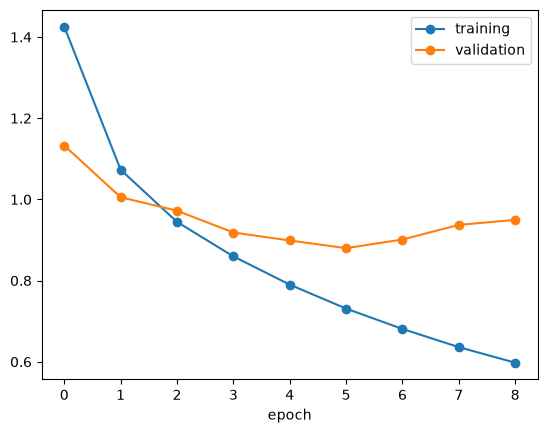

Epoch,Aika (s)
1,8.66
2,8.25
3,8.32
4,8.40
5,8.46
6,8.45
Keski suoritusaika,8.42
Kokonaissuoritusaika,76.78


In [15]:
import matplotlib.pyplot as plt

plt.plot(history_32_64_2layer.history["loss"], marker="o", label="training")
plt.plot(history_32_64_2layer.history["val_loss"], marker="o", label="validation")
plt.xlabel("epoch")
plt.legend()
plt.show()

# Epochien suoritusajat dataframeen huomioiden pysäyttäjä (poistetaan viimeiset 3 epochin suoritusaikaa).
df_times_32_64_2layer = pd.DataFrame({"Epoch": range(1, len(timer_32_64_2layer.epoch_times[:-3]) + 1), "Aika (s)": timer_32_64_2layer.epoch_times[:-3]})

# Keskimääräinen suoritusaika huomioiden pysäyttäjä (poistetaan viimeiset 3 epochin suoritusaikaa).
df_times_32_64_2layer.loc[len(df_times_32_64_2layer)] = ["Keski suoritusaika", sum(timer_32_64_2layer.epoch_times[:-3]) / len(timer_32_64_2layer.epoch_times[:-3])]

# Kokonaissuoritusaika koulutukselle.
df_times_32_64_2layer.loc[len(df_times_32_64_2layer)] = ["Kokonaissuoritusaika", sum(timer_32_64_2layer.epoch_times)]

# Pyöristetään ajat 2 tarkkuudella ja näytetään aikojen dataframe. Poistetaan turha indeksi visualisoinnin selkeyttämiseksi.
display(df_times_32_64_2layer.style.hide(axis="index").format({"Aika (s)": "{:.2f}"}))

#### 4.2.6 Johtopäätökset

Pysähdys tapahtui 8 epochin jälkeen, se ja kuvaaja indikoi epochille arvoa 5. Malli suoriutui validointi tarkkuudella 70,8% ja testitarkkuudella 75,05%, aika oli n. 80s. Malli toimii suhteellisen hyvin, mutta optimoitavaa vielä löytyy.

### 4.3 CNN-malli: 64 ja 128 suodatinta
Kokeillaan miten malli kehittyy kaksikerroksisella mallilla, jossa ensimmäinen kerros käyttää 64 suodattinta, antaen 64 piirrekarttaa ja toinen kerrot 128 suodatinta ja 128 eri piirrekarttaa. Kernel koolla 3 ja sisennys arvolla "same". Aktivointi on ReLU ja askelpituutena (stride) oletusarvo 1.

#### 4.3.1 Mallin rakentaminen

In [16]:
keras.utils.set_random_seed(0)
model64_128_2layer = keras.Sequential([
    keras.Input(shape=(32, 32, 3)),
    layers.Conv2D(64, kernel_size=3, padding="same", activation="relu"), # Ensimmäinen kerros 64 suodatinta
    layers.MaxPooling2D(pool_size=2),  # Puolitetaan piirrekarttojen korkeus ja leveys 16 x 16 x 64
    layers.Conv2D(128, kernel_size=3, padding="same", activation="relu"), # Toinen kerros 128 suodatinta
    layers.MaxPooling2D(pool_size=2), # Puolitetaan piirrekarttojen korkeus ja leveys 8 x 8 x 128
    layers.Flatten(),
    layers.Dense(10, activation="softmax")  # valitaan 10 luokan takia
])

#### 4.3.2 Mallin koulutusasetusten määrittäminen (compile)

Optimoijaksi valitaan adam, koska se muokkaa painokertoimien päivityksiä koulutuksen aikana ja pyrkii pienentämää loss-arvoa. Kokonaisluku luokituksen vuoksi (0-9) sparse_categorical_crossentropy parametri toimii parhaiten. Arviointi metriikka on tarkkuus (accuracy). Pysäytetään samaan tapaan kuin muissa.

In [17]:
model64_128_2layer.compile(optimizer="adam", loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])

#### 4.3.3 Mallin kouluttaminen

In [18]:
# Tallennetaan historia myöhempää tarkastelua varten.
history_64_128_2layer = model64_128_2layer.fit(x_train, y_train, epochs=20, validation_split=0.1, callbacks=[stop, timer_64_128_2layer])

# Tallennetaan ajat historiaan myöhempää tarkastelua varten.
history_64_128_2layer.history["epoch_time_seconds"] = timer_64_128_2layer.epoch_times

Epoch 1/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 21s 15ms/step - accuracy: 0.5199 - loss: 1.3566 - val_accuracy: 0.6364 - val_loss: 1.0504
Epoch 2/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 21s 15ms/step - accuracy: 0.6572 - loss: 0.9893 - val_accuracy: 0.6690 - val_loss: 0.9640
Epoch 3/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 22s 15ms/step - accuracy: 0.7059 - loss: 0.8521 - val_accuracy: 0.6948 - val_loss: 0.9096
Epoch 4/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 21s 15ms/step - accuracy: 0.7422 - loss: 0.7533 - val_accuracy: 0.7002 - val_loss: 0.9019
Epoch 5/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 22s 16ms/step - accuracy: 0.7729 - loss: 0.6709 - val_accuracy: 0.7050 - val_loss: 0.9143
Epoch 6/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 22s 16ms/step - accuracy: 0.7959 - loss: 0.6007 - val_accuracy: 0.7148 - val_loss: 0.8940
Epoch 7/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 22s 15ms/step - accuracy: 0.8173 - loss: 0.5378 - val_accuracy: 0.7134 - val_loss: 0.9466
Epoch 8/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 22s 15ms/step - accuracy: 0.8360 -

#### 4.3.4 Mallin arviointi

Vertaillaan CNN-mallien suorituskykyä testitarkkuuden (test accuracy), testihäviön (test loss), parametrimäärän ja koulutusajan perusteella. Lisäksi tarkastellaan parhaiden epochien koulutus- ja validointituloksia, jotta voidaan arvioida mallien tarkkuutta, ylisovittamista ja laskennallista tehokkuutta.

In [19]:
# Etsitään pienimmän validation lossin epoch
best_idx = np.argmin(history_64_128_2layer.history["val_loss"])

results_64_128 = [{
    "Malli": "64/128 (2 kerrosta)",
    "Paras epoch": best_idx + 1,
    "Training loss": history_64_128_2layer.history["loss"][best_idx],
    "Validation loss": history_64_128_2layer.history["val_loss"][best_idx],
    "Training accuracy": history_64_128_2layer.history["accuracy"][best_idx],
    "Validation accuracy": history_64_128_2layer.history["val_accuracy"][best_idx],
    "Koulutusaika (s)": sum(timer_64_128_2layer.epoch_times)
}]

df_results_64_128 = pd.DataFrame(results_64_128)

display(df_results_64_128.round(4))

,Malli,Paras epoch,Training loss,Validation loss,Training accuracy,Validation accuracy,Koulutusaika (s)
0,64/128 (2 kerrosta),6,0.6007,0.894,0.7959,0.7148,194.9196


#### 4.3.5 Tulosten visualisointi ja analysointi
Taulukoidaan mallin validointi menetys (validation loss) ja menetys (loss), ja mallin suoritusajat

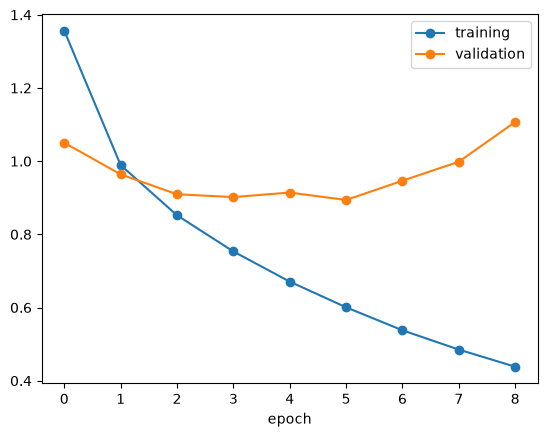

Epoch,Aika (s)
1,21.29
2,21.48
3,21.66
4,21.47
5,21.83
6,21.98
Keski suoritusaika,21.62
Kokonaissuoritusaika,194.92


In [20]:
plt.plot(history_64_128_2layer.history["loss"], marker="o", label="training")
plt.plot(history_64_128_2layer.history["val_loss"], marker="o", label="validation")
plt.xlabel("epoch")
plt.legend()
plt.show()

# Epochien suoritusajat dataframeen huomioiden pysäyttäjä (poistetaan viimeiset 3 epochin suoritusaikaa).
df_times_64_128_2layer = pd.DataFrame({"Epoch": range(1, len(timer_64_128_2layer.epoch_times[:-3]) + 1), "Aika (s)": timer_64_128_2layer.epoch_times[:-3]})

# Keskimääräinen suoritusaika huomioiden pysäyttäjä (poistetaan viimeiset 3 epochin suoritusaikaa).
df_times_64_128_2layer.loc[len(df_times_64_128_2layer)] = ["Keski suoritusaika", sum(timer_64_128_2layer.epoch_times[:-3]) / len(timer_64_128_2layer.epoch_times[:-3])]

# Kokonaissuoritusaika koulutukselle.
df_times_64_128_2layer.loc[len(df_times_64_128_2layer)] = ["Kokonaissuoritusaika", sum(timer_64_128_2layer.epoch_times)]

# Pyöristetään ajat 2 tarkkuudella ja näytetään aikojen dataframe. Poistetaan turha indeksi visualisoinnin selkeyttämiseksi.
display(df_times_64_128_2layer.style.hide(axis="index").format({"Aika (s)": "{:.2f}"}))

#### 4.3.6 Johtopäätökset

Aika nousi 64/32 malliin verrattuna lähes kolminkertaistuu. Tarkkuudet parani validaatiolla 71,48% ja testillä 79,59%. Konvulointi piirteiden nosto paransi hieman mallin suorituskykyä, mutta koulutusaika nousi huimasti verrattuna tarkkuuden nousuun.

### 4.4 CNN-malli: 16 ja 32 suodatinta

Kokeillaan miten pienempi suodatinmäärä vaikuttaa mallin tarkkuuteen ja suoritusaikaan. Ensimmäinen konvoluutiokerros käyttää 16 suodatinta ja toinen 32 suodatinta. Kernel koko on 3 ja padding-arvo "same". Aktivointina toimii ReLU ja askelpituutena (stride) oletusarvo 1.

#### 4.4.1 Mallin rakentaminen

In [21]:
keras.utils.set_random_seed(0)
model16_32_2layer = keras.Sequential([
    keras.Input(shape=(32, 32, 3)),
    layers.Conv2D(16, kernel_size=3, padding="same", activation="relu"), # Ensimmäinen kerros 16 suodatinta
    layers.MaxPooling2D(pool_size=2), # Puolitetaan piirrekarttojen korkeus ja leveys 16 x 16 x 16
    layers.Conv2D(32, kernel_size=3, padding="same", activation="relu"), # Toinen kerros 32 suodatinta
    layers.MaxPooling2D(pool_size=2), # Puolitetaan piirrekarttojen korkeus ja leveys 8 x 8 x 32
    layers.Flatten(),
    layers.Dense(10, activation="softmax") # Valitaan 10 luokan takia
])

#### 4.4.2 Mallin koulutusasetusten määrittäminen (compile)

Optimoijaksi valitaan Adam, joka päivittää mallin painokertoimia koulutuksen aikana pyrkien pienentämään loss-arvoa. Kokonaislukuluokituksen (0–9) vuoksi käytetään sparse_categorical_crossentropy-menetysfunktiota. Arviointimittarina toimii tarkkuus (accuracy). Koulutuksessa käytetään samaa EarlyStopping-menetelmää kuin muissa malleissa.

In [22]:
model16_32_2layer.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [23]:
#### 4.4.3 Mallin kouluttaminen

In [24]:
# Tallennetaan historia myöhempää tarkastelua varten
history_16_32_2layer = model16_32_2layer.fit(
    x_train,
    y_train,
    epochs=20,
    batch_size=32,
    validation_split=0.1,
    callbacks=[stop, timer_16_32_2layer]
)

# Tallennetaan ajat historiaan myöhempää tarkastelua varten
history_16_32_2layer.history["epoch_time_seconds"] = timer_16_32_2layer.epoch_times

Epoch 1/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.4537 - loss: 1.5374 - val_accuracy: 0.5660 - val_loss: 1.2538
Epoch 2/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.5818 - loss: 1.2022 - val_accuracy: 0.6128 - val_loss: 1.1228
Epoch 3/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.6278 - loss: 1.0748 - val_accuracy: 0.6380 - val_loss: 1.0537
Epoch 4/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.6564 - loss: 0.9962 - val_accuracy: 0.6532 - val_loss: 1.0132
Epoch 5/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.6742 - loss: 0.9431 - val_accuracy: 0.6652 - val_loss: 0.9817
Epoch 6/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.6890 - loss: 0.9009 - val_accuracy: 0.6762 - val_loss: 0.9580
Epoch 7/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.7025 - loss: 0.8661 - val_accuracy: 0.6806 - val_loss: 0.9441
Epoch 8/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.7117 - loss: 0.8367 - 

#### 4.4.4 Mallin arviointi

Vertaillaan CNN-mallien suorituskykyä testitarkkuuden (test accuracy), testihäviön (test loss), parametrimäärän ja koulutusajan perusteella. Lisäksi tarkastellaan parhaiden epochien koulutus- ja validointituloksia, jotta voidaan arvioida mallien tarkkuutta, ylisovittamista ja laskennallista tehokkuutta.

In [25]:
# Etsitään pienimmän validation lossin epoch
best_idx = np.argmin(history_16_32_2layer.history["val_loss"])

results_16_32 = [{
    "Malli": "16/32 (2 kerrosta)",
    "Paras epoch": best_idx + 1,
    "Training loss": history_16_32_2layer.history["loss"][best_idx],
    "Validation loss": history_16_32_2layer.history["val_loss"][best_idx],
    "Training accuracy": history_16_32_2layer.history["accuracy"][best_idx],
    "Validation accuracy": history_16_32_2layer.history["val_accuracy"][best_idx],
    "Koulutusaika (s)": sum(timer_16_32_2layer.epoch_times)
}]

df_results_16_32 = pd.DataFrame(results_16_32)

display(df_results_16_32.round(4))

,Malli,Paras epoch,Training loss,Validation loss,Training accuracy,Validation accuracy,Koulutusaika (s)
0,16/32 (2 kerrosta),11,0.7669,0.9266,0.7356,0.6898,71.9814


#### 4.4.5 Tulosten visualisointi ja analysointi

Visualisoidaan mallin harjoitusdatan menetys (loss) ja validointidatan menetys (validation loss). Lisäksi taulukoidaan epochien suoritusajat, keskimääräinen suoritusaika ja koulutuksen kokonaisaika.

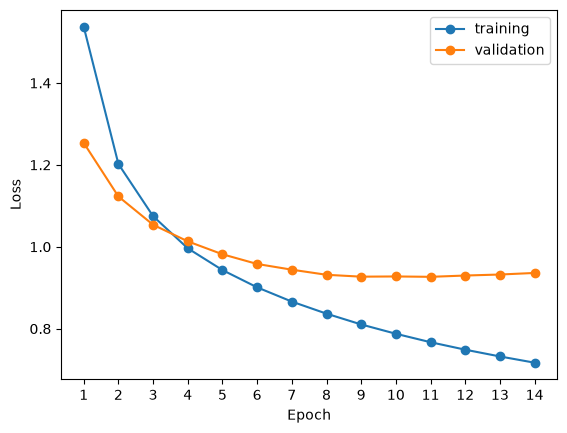

Epoch,Aika (s)
1,5.72
2,5.51
3,5.29
4,5.46
5,5.10
6,5.10
7,4.96
8,5.04
9,4.89
10,5.06


In [26]:
epochs = range(1, len(history_16_32_2layer.history["loss"]) + 1)

plt.plot(epochs, history_16_32_2layer.history["loss"], marker="o", label="training")
plt.plot(epochs, history_16_32_2layer.history["val_loss"], marker="o", label="validation")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.xticks(epochs)
plt.legend()
plt.show()

# Epochien suoritusajat dataframeen
df_times_16_32_2layer = pd.DataFrame({
    "Epoch": range(1, len(timer_16_32_2layer.epoch_times) + 1),
    "Aika (s)": timer_16_32_2layer.epoch_times
})

# Keskimääräinen suoritusaika huomioiden pysäyttäjä (poistetaan viimeiset 3 epochin suoritusaikaa).
df_times_16_32_2layer.loc[len(df_times_16_32_2layer)] = [
    "Keski suoritusaika",
    sum(timer_16_32_2layer.epoch_times[:-3]) / len(timer_16_32_2layer.epoch_times[:-3])
]

# Kokonaissuoritusaika
df_times_16_32_2layer.loc[len(df_times_16_32_2layer)] = [
    "Kokonaissuoritusaika",
    sum(timer_16_32_2layer.epoch_times)
]

# Näytetään dataframe ilman indeksejä
display(
    df_times_16_32_2layer.style
    .hide(axis="index")
    .format({"Aika (s)": "{:.2f}"})
)

#### 4.4.6 Johtopäätökset

16/32-malli saavutti testitarkkuuden 68,00 % ja validointitarkkuuden 68,98 %. Paras validation loss (0,9266) saavutettiin epochilla 11 ja koulutus pysähtyi 14 epochin jälkeen. Koulutuksen kokonaisaika oli noin 94 sekuntia ja opetettavia parametreja oli 25 578.

32/64-malli saavutti testitarkkuuden 69,60 % ja validointitarkkuuden 70,80 %. Paras validation loss (0,8798) saavutettiin epochilla 6. Koulutuksen kokonaisaika oli noin 80 sekuntia ja parametreja oli 60 362. Verrattuna 16/32-malliin testitarkkuus parani **1,60 prosenttiyksikköä** ja validointitarkkuus **1,82 prosenttiyksikköä**. Koulutusaika oli myös noin 14 % lyhyempi, vaikka parametrimäärä oli yli kaksinkertainen. Aika paranee selkeästi, kun kierrosmäärä laskee 14:sta 8:an.

64/128-malli saavutti aiemmassa testiarvioinnissa testitarkkuuden 70,18 % ja koulutuksessa validointitarkkuuden 71,48 %. Paras validation loss (0,8940) saavutettiin epochilla 6. Koulutuksen kokonaisaika oli noin kolmin kertainen verrattuna kevyempään 32/64-malliin. Verrattuna 32/64-malliin testitarkkuus oli **0,58 prosenttiyksikköä** ja validointitarkkuus **0,68 prosenttiyksikköä** parempi. Lisäksi validation loss oli hieman suurempi kuin 32/64-mallilla.

#### 4.4.7 Loppuyhteenveto

32/64-malli osoittautui näistä kolmesta parhaaksi vaihtoehdoksi tarkkuuden ja koulutusajan suhteen. Pienempi 16/32-malli oli parametrimäärältään kevyempi, mutta sen testitarkkuus jäi **1,60 prosenttiyksikköä** ja validointitarkkuus **1,82 prosenttiyksikköä** heikommaksi. Myöskään kokonaiskoulutusaika ei lyhentynyt.

Suurempi 64/128-malli saavutti parhaat tarkkuudet, mutta parannukset jäivät alle yhden prosenttiyksikön suhteessa 32/64-malliin. Samalla koulutusaika lähes kolminkertaistui ja parametrimäärä kasvoi merkittävästi.

Tulosten perusteella **32/64-malli valitaan kaksikerroksisten CNN-mallien parhaaksi vaihtoehdoksi** jatkovertailua varten, sillä sen tarkkuus oli lähellä suuremman mallin tuloksia huomattavasti pienemmällä laskentakustannuksella.

### 4.5 CNN-malli: 32 ja 64 suodatinta: kolmas ja neljäs kerros.
Kokeillaan miten malli kehittyy kerroksia kasvattaessa kahdesta kolmeen. Pidetään samat määritteet, eli ensimmäinen kerros käyttää 32 suodattinta, antaen 32 piirrekarttaa. Lisätään toinen Conv2D(32) kerros väliin ja kolmas kerros sama 64 suodatinta ja 64 eri piirrekarttaa. Kernel koolla 3 ja sisennys arvolla "same". Aktivointi on ReLU ja askelpituutena (stride) oletusarvo 1.

#### 4.5.1 Mallin rakentaminen: 3 kerrosta 32/32/64

In [27]:
model32_32_64_3layer = keras.Sequential([
    keras.Input(shape=(32, 32, 3)),
    layers.Conv2D(32, kernel_size=3, padding="same", activation="relu"), # Ensimmäinen kerros 32 suodatinta
    layers.Conv2D(32, kernel_size=3, padding="same", activation="relu"), # Toinen kerros 32 suodatinta
    layers.MaxPooling2D(pool_size=2), # Puolitetaan piirrekarttojen korkeus ja leveys 16 x 16 x 32
    layers.Conv2D(64, kernel_size=3, padding="same", activation="relu"), # Kolmas kerros 64 suodatinta
    layers.MaxPooling2D(pool_size=2), # Puolitetaan piirrekarttojen korkeus ja leveys 8 x 8 x 64
    layers.Flatten(),
    layers.Dense(10, activation="softmax") # Valitaan 10 luokan takia
])

#### 4.5.2 Mallin koulutusasetusten määrittäminen (compile)

Optimoijaksi valitaan Adam, joka päivittää mallin painokertoimia koulutuksen aikana pyrkien pienentämään loss-arvoa. Kokonaislukuluokituksen (0–9) vuoksi käytetään sparse_categorical_crossentropy-menetysfunktiota. Arviointimittarina toimii tarkkuus (accuracy). Koulutuksessa käytetään samaa EarlyStopping-menetelmää kuin muissa malleissa.

In [28]:
model32_32_64_3layer.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

#### 4.5.3 Mallin kouluttaminen

In [29]:
# Tallennetaan historia myöhempää tarkastelua varten
history_32_32_64_3layer = model32_32_64_3layer.fit(
    x_train,
    y_train,
    epochs=20,
    batch_size=32,
    validation_split=0.1,
    callbacks=[stop, timer_32_32_64_3layer]
)

# Tallennetaan ajat historiaan myöhempää tarkastelua varten
history_32_32_64_3layer.history["epoch_time_seconds"] = timer_32_32_64_3layer.epoch_times

Epoch 1/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 20s 14ms/step - accuracy: 0.5090 - loss: 1.3803 - val_accuracy: 0.6464 - val_loss: 1.0319
Epoch 2/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 19s 14ms/step - accuracy: 0.6652 - loss: 0.9677 - val_accuracy: 0.6968 - val_loss: 0.8949
Epoch 3/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 19s 14ms/step - accuracy: 0.7172 - loss: 0.8220 - val_accuracy: 0.7194 - val_loss: 0.8345
Epoch 4/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 20s 14ms/step - accuracy: 0.7535 - loss: 0.7223 - val_accuracy: 0.7282 - val_loss: 0.8275
Epoch 5/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 20s 14ms/step - accuracy: 0.7813 - loss: 0.6429 - val_accuracy: 0.7274 - val_loss: 0.8498
Epoch 6/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 20s 14ms/step - accuracy: 0.8052 - loss: 0.5761 - val_accuracy: 0.7294 - val_loss: 0.8609
Epoch 7/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 20s 14ms/step - accuracy: 0.8236 - loss: 0.5184 - val_accuracy: 0.7272 - val_loss: 0.9061


#### 4.5.4 Mallin arviointi

Vertaillaan CNN-mallien suorituskykyä testitarkkuuden (test accuracy), testihäviön (test loss), parametrimäärän ja koulutusajan perusteella. Lisäksi tarkastellaan parhaiden epochien koulutus- ja validointituloksia, jotta voidaan arvioida mallien tarkkuutta, ylisovittamista ja laskennallista tehokkuutta.

In [30]:
# Etsitään pienimmän validation lossin epoch
best_idx = np.argmin(history_32_32_64_3layer.history["val_loss"])

results_32_32_64 = [{
    "Malli": "32/32/64 (3 kerrosta)",
    "Paras epoch": best_idx + 1,
    "Training loss": history_32_32_64_3layer.history["loss"][best_idx],
    "Validation loss": history_32_32_64_3layer.history["val_loss"][best_idx],
    "Training accuracy": history_32_32_64_3layer.history["accuracy"][best_idx],
    "Validation accuracy": history_32_32_64_3layer.history["val_accuracy"][best_idx],
    "Koulutusaika (s)": sum(timer_32_32_64_3layer.epoch_times)
}]

df_results_32_32_64 = pd.DataFrame(results_32_32_64)

display(df_results_32_32_64.round(4))

,Malli,Paras epoch,Training loss,Validation loss,Training accuracy,Validation accuracy,Koulutusaika (s)
0,32/32/64 (3 kerrosta),4,0.7223,0.8275,0.7535,0.7282,137.2078


#### 4.5.5 Tulosten visualisointi ja analysointi

Visualisoidaan mallin harjoitusdatan menetys (loss) ja validointidatan menetys (validation loss). Lisäksi taulukoidaan epochien suoritusajat, keskimääräinen suoritusaika ja koulutuksen kokonaisaika.

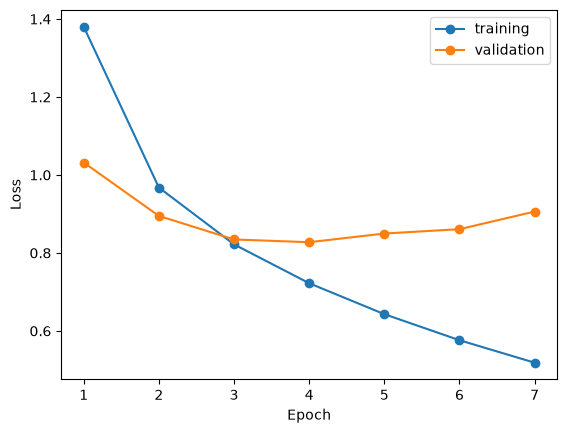

Epoch,Aika (s)
1,19.73
2,19.44
3,19.42
4,19.70
5,19.74
6,19.61
7,19.57
Keski suoritusaika,19.57
Kokonaissuoritusaika,137.21


In [31]:
epochs = range(1, len(history_32_32_64_3layer.history["loss"]) + 1)

plt.plot(epochs, history_32_32_64_3layer.history["loss"], marker="o", label="training")
plt.plot(epochs, history_32_32_64_3layer.history["val_loss"], marker="o", label="validation")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.xticks(epochs)
plt.legend()
plt.show()

# Epochien suoritusajat dataframeen
df_times_32_32_64_3layer = pd.DataFrame({
    "Epoch": range(1, len(timer_32_32_64_3layer.epoch_times) + 1),
    "Aika (s)": timer_32_32_64_3layer.epoch_times
})

# Keskimääräinen suoritusaika huomioiden pysäyttäjä (poistetaan viimeiset 3 epochin suoritusaikaa).
df_times_32_32_64_3layer.loc[len(df_times_32_32_64_3layer)] = [
    "Keski suoritusaika",
    sum(timer_32_32_64_3layer.epoch_times[:-3]) / len(timer_32_32_64_3layer.epoch_times[:-3])
]

# Kokonaissuoritusaika
df_times_32_32_64_3layer.loc[len(df_times_32_32_64_3layer)] = [
    "Kokonaissuoritusaika",
    sum(timer_32_32_64_3layer.epoch_times)
]

# Näytetään dataframe ilman indeksejä
display(
    df_times_32_32_64_3layer.style
    .hide(axis="index")
    .format({"Aika (s)": "{:.2f}"})
)

## 4.6.1 Mallin rakentaminen: 32/32/64/64

Kokeillaan tuoko neljäs kerros 64 suodattimella tarkkuutta suhteessa suoritusaikaan.

In [32]:
keras.utils.set_random_seed(0)

model32_32_64_64_4layer = keras.Sequential([
    keras.Input(shape=(32, 32, 3)),
    layers.Conv2D(32, kernel_size=3, padding="same", activation="relu"), # Ensimmäinen kerros 32 suodatinta
    layers.Conv2D(32, kernel_size=3, padding="same", activation="relu"), # Toinen kerros 32 suodatinta
    layers.MaxPooling2D(pool_size=2), # Puolitetaan piirrekarttojen korkeus ja leveys 16 x 16 x 32
    layers.Conv2D(64, kernel_size=3, padding="same", activation="relu"), # Kolmas kerros 64 suodatinta
    layers.Conv2D(64, kernel_size=3, padding="same", activation="relu"), # Neljäs kerros 64 suodatinta
    layers.MaxPooling2D(pool_size=2), # Puolitetaan piirrekarttojen korkeus ja leveys 8 x 8 x 64
    layers.Flatten(),
    layers.Dense(10, activation="softmax") # 10 neuronia CIFAR-10:n luokkia varten
])

#### 4.6.2 Mallin koulutusasetusten määrittäminen (compile)

Optimoijaksi valitaan Adam, joka päivittää mallin painokertoimia koulutuksen aikana pyrkien pienentämään loss-arvoa. Kokonaislukuluokituksen (0–9) vuoksi käytetään sparse_categorical_crossentropy-menetysfunktiota. Arviointimittarina toimii tarkkuus (accuracy). Koulutuksessa käytetään samaa EarlyStopping-menetelmää kuin muissa malleissa.

In [33]:
model32_32_64_64_4layer.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

#### 4.6.3 Mallin kouluttaminen

In [34]:
# Tallennetaan historia myöhempää tarkastelua varten
history_32_32_64_64_4layer = model32_32_64_64_4layer.fit(
    x_train,
    y_train,
    epochs=20,
    batch_size=32,
    validation_split=0.1,
    callbacks=[stop, timer_32_32_64_64_4layer]
)

# Tallennetaan ajat historiaan myöhempää tarkastelua varten
history_32_32_64_64_4layer.history["epoch_time_seconds"] = timer_32_32_64_64_4layer.epoch_times

Epoch 1/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 28s 20ms/step - accuracy: 0.4985 - loss: 1.3931 - val_accuracy: 0.6280 - val_loss: 1.0518
Epoch 2/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 28s 20ms/step - accuracy: 0.6694 - loss: 0.9409 - val_accuracy: 0.7024 - val_loss: 0.8644
Epoch 3/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 28s 20ms/step - accuracy: 0.7320 - loss: 0.7748 - val_accuracy: 0.7230 - val_loss: 0.8199
Epoch 4/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 28s 20ms/step - accuracy: 0.7680 - loss: 0.6684 - val_accuracy: 0.7312 - val_loss: 0.8254
Epoch 5/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 27s 19ms/step - accuracy: 0.7973 - loss: 0.5858 - val_accuracy: 0.7348 - val_loss: 0.8776
Epoch 6/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 28s 20ms/step - accuracy: 0.8208 - loss: 0.5183 - val_accuracy: 0.7306 - val_loss: 0.9430


#### 4.6.4 Mallin arviointi

Vertaillaan CNN-mallien suorituskykyä testitarkkuuden (test accuracy), testihäviön (test loss), parametrimäärän ja koulutusajan perusteella. Lisäksi tarkastellaan parhaiden epochien koulutus- ja validointituloksia, jotta voidaan arvioida mallien tarkkuutta, ylisovittamista ja laskennallista tehokkuutta.

In [35]:
# Etsitään pienimmän validation lossin epoch
best_idx = np.argmin(history_32_32_64_64_4layer.history["val_loss"])

results_32_32_64_64 = [{
    "Malli": "32/32/64/64 (4 kerrosta)",
    "Paras epoch": best_idx + 1,
    "Training loss": history_32_32_64_64_4layer.history["loss"][best_idx],
    "Validation loss": history_32_32_64_64_4layer.history["val_loss"][best_idx],
    "Training accuracy": history_32_32_64_64_4layer.history["accuracy"][best_idx],
    "Validation accuracy": history_32_32_64_64_4layer.history["val_accuracy"][best_idx],
    "Koulutusaika (s)": sum(timer_32_32_64_64_4layer.epoch_times)
}]

df_results_32_32_64_64 = pd.DataFrame(results_32_32_64_64)

display(df_results_32_32_64_64.round(4))

,Malli,Paras epoch,Training loss,Validation loss,Training accuracy,Validation accuracy,Koulutusaika (s)
0,32/32/64/64 (4 kerrosta),3,0.7748,0.8199,0.732,0.723,166.732


#### 4.6.5 Tulosten visualisointi ja analysointi

Visualisoidaan mallin harjoitusdatan menetys (loss) ja validointidatan menetys (validation loss). Lisäksi taulukoidaan epochien suoritusajat, keskimääräinen suoritusaika ja koulutuksen kokonaisaika.

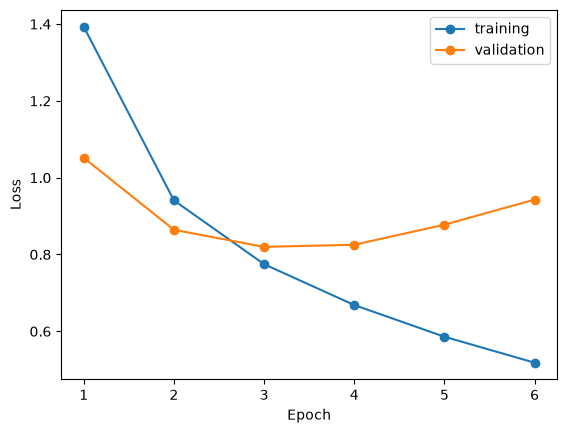

Epoch,Aika (s)
1,28.20
2,27.73
3,27.82
4,27.88
5,27.24
6,27.85
Keski suoritusaika,27.92
Kokonaissuoritusaika,166.73


In [36]:
# Loss-arvojen visualisointi
epochs = range(1, len(history_32_32_64_64_4layer.history["loss"]) + 1)

plt.plot(epochs, history_32_32_64_64_4layer.history["loss"], marker="o", label="training")
plt.plot(epochs, history_32_32_64_64_4layer.history["val_loss"], marker="o", label="validation")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.xticks(epochs)
plt.legend()
plt.show()

# Epochien suoritusajat dataframeen
df_times_32_32_64_64_4layer = pd.DataFrame({
    "Epoch": range(1, len(timer_32_32_64_64_4layer.epoch_times) + 1),
    "Aika (s)": timer_32_32_64_64_4layer.epoch_times
})

# Keskimääräinen suoritusaika (poistetaan viimeiset 3 epochia)
df_times_32_32_64_64_4layer.loc[len(df_times_32_32_64_64_4layer)] = [
    "Keski suoritusaika",
    sum(timer_32_32_64_64_4layer.epoch_times[:-3]) / len(timer_32_32_64_64_4layer.epoch_times[:-3])
]

# Kokonaissuoritusaika
df_times_32_32_64_64_4layer.loc[len(df_times_32_32_64_64_4layer)] = [
    "Kokonaissuoritusaika",
    sum(timer_32_32_64_64_4layer.epoch_times)
]

# Näytetään dataframe ilman indeksejä
display(
    df_times_32_32_64_64_4layer.style
    .hide(axis="index")
    .format({"Aika (s)": "{:.2f}"})
)

#### 4.7.1 Mallin rakentaminen: 3 kerrosta 64/64/128

Katsotaan miten kolmikerroksinen malli toimii arvoilla 64/64/128.

In [37]:
keras.utils.set_random_seed(0)

model64_64_128_3layer = keras.Sequential([
    keras.Input(shape=(32, 32, 3)),
    layers.Conv2D(64, kernel_size=3, padding="same", activation="relu"), # Ensimmäinen kerros 64 suodatinta
    layers.Conv2D(64, kernel_size=3, padding="same", activation="relu"), # Toinen kerros 64 suodatinta
    layers.MaxPooling2D(pool_size=2), # Puolitetaan piirrekarttojen korkeus ja leveys 16 x 16 x 64
    layers.Conv2D(128, kernel_size=3, padding="same", activation="relu"), # Kolmas kerros 128 suodatinta
    layers.MaxPooling2D(pool_size=2), # Puolitetaan piirrekarttojen korkeus ja leveys 8 x 8 x 128
    layers.Flatten(),
    layers.Dense(10, activation="softmax") # 10 neuronia CIFAR-10:n luokkia varten
])

#### 4.7.2 Mallin koulutusasetusten määrittäminen (compile)

Optimoijaksi valitaan Adam, joka päivittää mallin painokertoimia koulutuksen aikana pyrkien pienentämään loss-arvoa. Kokonaislukuluokituksen (0–9) vuoksi käytetään sparse_categorical_crossentropy-menetysfunktiota. Arviointimittarina toimii tarkkuus (accuracy). Koulutuksessa käytetään samaa EarlyStopping-menetelmää kuin muissa malleissa.

In [38]:
model64_64_128_3layer.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

#### 4.7.3 Mallin kouluttaminen

In [39]:
# Tallennetaan historia myöhempää tarkastelua varten
history_64_64_128_3layer = model64_64_128_3layer.fit(
    x_train,
    y_train,
    epochs=20,
    batch_size=32,
    validation_split=0.1,
    callbacks=[stop, timer_64_64_128_3layer]
)

# Tallennetaan ajat historiaan myöhempää tarkastelua varten
history_64_64_128_3layer.history["epoch_time_seconds"] = timer_64_64_128_3layer.epoch_times

Epoch 1/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 50s 36ms/step - accuracy: 0.5349 - loss: 1.3130 - val_accuracy: 0.6708 - val_loss: 0.9540
Epoch 2/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 50s 35ms/step - accuracy: 0.6975 - loss: 0.8742 - val_accuracy: 0.7142 - val_loss: 0.8492
Epoch 3/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 50s 36ms/step - accuracy: 0.7557 - loss: 0.7109 - val_accuracy: 0.7160 - val_loss: 0.8741
Epoch 4/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 51s 36ms/step - accuracy: 0.7965 - loss: 0.5956 - val_accuracy: 0.7230 - val_loss: 0.8908
Epoch 5/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 52s 37ms/step - accuracy: 0.8259 - loss: 0.5085 - val_accuracy: 0.7240 - val_loss: 0.9593


#### 4.7.4 Mallin arviointi

Vertaillaan CNN-mallien suorituskykyä testitarkkuuden (test accuracy), testihäviön (test loss), parametrimäärän ja koulutusajan perusteella. Lisäksi tarkastellaan parhaiden epochien koulutus- ja validointituloksia, jotta voidaan arvioida mallien tarkkuutta, ylisovittamista ja laskennallista tehokkuutta.

In [40]:
# Etsitään pienimmän validation lossin epoch
best_idx = np.argmin(history_64_64_128_3layer.history["val_loss"])

results_64_64_128 = [{
    "Malli": "64/64/128 (3 kerrosta)",
    "Paras epoch": best_idx + 1,
    "Training loss": history_64_64_128_3layer.history["loss"][best_idx],
    "Validation loss": history_64_64_128_3layer.history["val_loss"][best_idx],
    "Training accuracy": history_64_64_128_3layer.history["accuracy"][best_idx],
    "Validation accuracy": history_64_64_128_3layer.history["val_accuracy"][best_idx],
    "Koulutusaika (s)": sum(timer_64_64_128_3layer.epoch_times)
}]

df_results_64_64_128 = pd.DataFrame(results_64_64_128)

display(df_results_64_64_128.round(4))

,Malli,Paras epoch,Training loss,Validation loss,Training accuracy,Validation accuracy,Koulutusaika (s)
0,64/64/128 (3 kerrosta),2,0.8742,0.8492,0.6975,0.7142,253.5153


#### 4.7.5 Tulosten visualisointi ja analysointi

Visualisoidaan mallin harjoitusdatan menetys (loss) ja validointidatan menetys (validation loss). Lisäksi taulukoidaan epochien suoritusajat, keskimääräinen suoritusaika ja koulutuksen kokonaisaika.

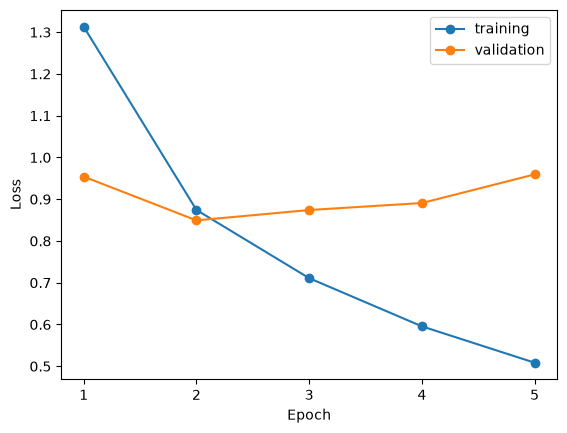

Epoch,Aika (s)
1,50.43
2,49.69
3,50.45
4,51.03
5,51.93
Keski suoritusaika,50.06
Kokonaissuoritusaika,253.52


In [41]:
# Loss-arvojen visualisointi
epochs = range(1, len(history_64_64_128_3layer.history["loss"]) + 1)

plt.plot(epochs, history_64_64_128_3layer.history["loss"], marker="o", label="training")
plt.plot(epochs, history_64_64_128_3layer.history["val_loss"], marker="o", label="validation")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.xticks(epochs)
plt.legend()
plt.show()

# Epochien suoritusajat dataframeen
df_times_64_64_128_3layer = pd.DataFrame({
    "Epoch": range(1, len(timer_64_64_128_3layer.epoch_times) + 1),
    "Aika (s)": timer_64_64_128_3layer.epoch_times
})

# Keskimääräinen suoritusaika ilman kolmea viimeistä epochia
df_times_64_64_128_3layer.loc[len(df_times_64_64_128_3layer)] = [
    "Keski suoritusaika",
    sum(timer_64_64_128_3layer.epoch_times[:-3]) / len(timer_64_64_128_3layer.epoch_times[:-3])
]

# Kokonaissuoritusaika
df_times_64_64_128_3layer.loc[len(df_times_64_64_128_3layer)] = [
    "Kokonaissuoritusaika",
    sum(timer_64_64_128_3layer.epoch_times)
]

# Näytetään dataframe ilman indeksejä
display(
    df_times_64_64_128_3layer.style
    .hide(axis="index")
    .format({"Aika (s)": "{:.2f}"})
)

#### 4.7.6 Johtopäätökset

Mallin kerroksien nosto arvoille 64/64/128 laski koulutussuorituskykyä. Saa heikommat test ja val accuracyt, kuin 3 kerroksinen 32/32/64, ja hitaampi suorittaa.

In [42]:
df_comparison = pd.concat([
    df_results_16_32,
    df_results_32_64,
    df_results_64_128,
    df_results_32_32_64,
    df_results_64_64_128,
    df_results_32_32_64_64
], ignore_index=True)

display(df_comparison.round(4))

,Malli,Paras epoch,Training loss,Validation loss,Training accuracy,Validation accuracy,Koulutusaika (s)
0,16/32 (2 kerrosta),11,0.7669,0.9266,0.7356,0.6898,71.9814
1,32/64 (2 kerrosta),6,0.7310,0.8798,0.7505,0.7080,76.7823
2,64/128 (2 kerrosta),6,0.6007,0.8940,0.7959,0.7148,194.9196
3,32/32/64 (3 kerrosta),4,0.7223,0.8275,0.7535,0.7282,137.2078
4,64/64/128 (3 kerrosta),2,0.8742,0.8492,0.6975,0.7142,253.5153
5,32/32/64/64 (4 kerrosta),3,0.7748,0.8199,0.7320,0.7230,166.7320


#### 4.8 Johtopäätökset

Mallien vertailussa havaittiin, että suodattimien ja kerrosten määrän lisääminen ei automaattisesti paranna tarkkuutta. Paras validointitarkkuus (72,82 %) saavutettiin kolmikerroksisella `32/32/64`-mallilla. Verrattuna kaksikerroksiseen `32/64`-malliin tarkkuus parani 2,02 prosenttiyksikköä, mutta koulutusaika kasvoi noin 79 %.

Suuremmat `64/64/128`- ja `32/32/64/64`-mallit eivät parantaneet validointitarkkuutta, vaikka koulutusajat kasvoivat. Nelikerroksinen malli saavutti kuitenkin hieman pienemmän validation loss -arvon.

Jatkokehitykseen valitaan `32/32/64`-malli, koska se saavutti parhaan validointitarkkuuden kohtuullisella koulutusajalla. Seuraavaksi voidaan tutkia muiden optimointimenetelmien vaikutusta mallin suorituskykyyn.

# 5. Arviointi

## 5.1 Neuronien määrä ja kerrosten määrä

### 5.1.1 Neuronimäärien ja kerrosten määrien kokeilu

Arvioidaan mallien suorituskyky testidataan ja vertaillaan niitä yhdessä dataframessa.

In [43]:
import pandas as pd

# Määritetään vertailtavat mallit ja niiden ajastimet
models = {
    "16/32 (2 kerrosta)": (model16_32_2layer, timer_16_32_2layer),
    "32/64 (2 kerrosta)": (model32_64_2layer, timer_32_64_2layer),
    "64/128 (2 kerrosta)": (model64_128_2layer, timer_64_128_2layer),
    "32/32/64 (3 kerrosta)": (model32_32_64_3layer, timer_32_32_64_3layer),
    "64/64/128 (3 kerrosta)": (model64_64_128_3layer, timer_64_64_128_3layer),
    "32/32/64/64 (4 kerrosta)": (model32_32_64_64_4layer, timer_32_32_64_64_4layer)
}

results = []

# Arvioidaan jokainen malli testidatalla
for name, (model, timer) in models.items():
    test_loss, test_accuracy = model.evaluate(x_test, y_test, verbose=0)

    results.append({
        "Malli": name,
        "Test loss": test_loss,
        "Test accuracy (%)": test_accuracy * 100,
        "Parametrit": model.count_params(),
        "Kokonaissuoritusaika (s)": sum(timer.epoch_times)
    })

# Muodostetaan DataFrame
df_evaluation = pd.DataFrame(results)

# Näytetään tulokset ilman indeksiä
display(
    df_evaluation.style
    .hide(axis="index")
    .format({
        "Test loss": "{:.4f}",
        "Test accuracy (%)": "{:.2f}",
        "Parametrit": "{:,}",
        "Kokonaissuoritusaika (s)": "{:.2f}"
    })
)

Malli,Test loss,Test accuracy (%),Parametrit,Kokonaissuoritusaika (s)
16/32 (2 kerrosta),0.9525,68.00,"25,578",71.98
32/64 (2 kerrosta),0.9040,69.60,"60,362",76.78
64/128 (2 kerrosta),0.9590,69.48,"157,578",194.92
32/32/64 (3 kerrosta),0.8667,70.89,"69,610",137.21
64/64/128 (3 kerrosta),0.8721,69.89,"194,506",253.52
32/32/64/64 (4 kerrosta),0.8676,70.68,"106,538",166.73


### 5.1.2 Johtopäätökset

Suodattimien ja kerrosten lisääminen ei automaattisesti parantanut mallien tarkkuutta. Paras testitarkkuus **70,89 %** ja pienin test loss **0,8667** saavutettiin kolmikerroksisella `32/32/64`-mallilla.

Verrattuna kaksikerroksiseen `32/64`-malliin tarkkuus parani **1,29 prosenttiyksikköä**, mutta koulutusaika kasvoi noin 79 %. Suuremmat mallit eivät parantaneet tulosta suhteessa kasvaneeseen koulutusaikaan.